# Four-frequency HILC → anisotropic rotation reconstruction
This notebook combines a **toy four-frequency experiment** with HILC and reconstructs $C_L^{\alpha\alpha}$ using `AlphaRecon` and Plancklens `a_p`.

Frequency labels identify channels; the current sky contains CMB plus independent white noise, **no foregrounds**. All channels share the same anisotropic rotation. Miscalibration is zero here to isolate that signal. Beam widths and noise levels below are illustrative rather than specifications of a real instrument.

We show weights, cleaned T/E/B spectra, residual noise, and rotation reconstruction. Separate simulation indices estimate the mean HILC noise used in the inverse-variance filters. Outputs are cached under `data/`; parameters are editable in the next cell.

In [1]:
%matplotlib inline
import hashlib
import json
from pathlib import Path
import time

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sim import CMBobs
from hilc import HILC
from recon import AlphaRecon

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
freqs = np.array([90, 150, 220, 280])  # GHz: channel labels
nlevp = np.array([5., 3., 4., 8.])     # uK-arcmin
fwhm = np.array([40., 30., 20., 15.])  # arcmin
alpha = None                        # no channel miscalibration (degrees)
Acb = 1e-5                          # rad²; shared spatial rotation amplitude
nside = 128
lmax_hilc = 256
hilc_bin_width = 32
lmin_ivf = 20
lmax_ivf = 256
lmax_qlm = 64
noise_indices = tuple(range(100, 108))  # filtering calibration ensemble
sim_indices = tuple(range(8))          # reconstruction ensemble
rotation_bin_width = 8
assert not set(noise_indices).intersection(sim_indices)
assert len(sim_indices) >= 2
assert len(freqs) == len(nlevp) == len(fwhm) == 4

config = dict(freqs=freqs.tolist(), nlevp=nlevp.tolist(), fwhm=fwhm.tolist(),
              alpha=alpha, Acb=Acb, nside=nside, lmax_hilc=lmax_hilc,
              hilc_bin_width=hilc_bin_width, lmin_ivf=lmin_ivf,
              lmax_ivf=lmax_ivf, lmax_qlm=lmax_qlm, noise_indices=noise_indices)
tag = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
root = Path('data') / 'four_frequency_demo' / tag
obs = CMBobs(nside, nlevp, fwhm, alpha=alpha, Acb=Acb)
hilc = HILC(obs, root / 'hilc', lmax=lmax_hilc, bin_width=hilc_bin_width)
rows = ['| Frequency (GHz) | FWHM (arcmin) | Polarization noise (µK-arcmin) |',
        '|---:|---:|---:|']
rows += [f'| {f} | {b:g} | {n:g} |' for f, b, n in zip(freqs, fwhm, nlevp)]
display(Markdown('\n'.join(rows)))
print(f'nside={nside}, Acb={Acb:g} rad², cache={root}')

| Frequency (GHz) | FWHM (arcmin) | Polarization noise (µK-arcmin) |
|---:|---:|---:|
| 90 | 40 | 5 |
| 150 | 30 | 3 |
| 220 | 20 | 4 |
| 280 | 15 | 8 |

nside=128, Acb=1e-05 rad², cache=data/four_frequency_demo/94a02d77d1df


## HILC weights
Each channel is first deconvolved by its polarized Gaussian beam. Within each multipole bin, separate T, E, B weights minimize empirical variance with $\sum_\nu w_\nu=1$. Negative weights are allowed. These are **observed-sky weights**, and the exact same weights are applied to the actual noise realizations.

Empirical weights can correlate with the CMB, leading to ILC signal bias. The unit-sum constraint does not guarantee an unbiased recovered power spectrum. Wide bins reduce sampling fluctuations; the small experiment below is a diagnostic.

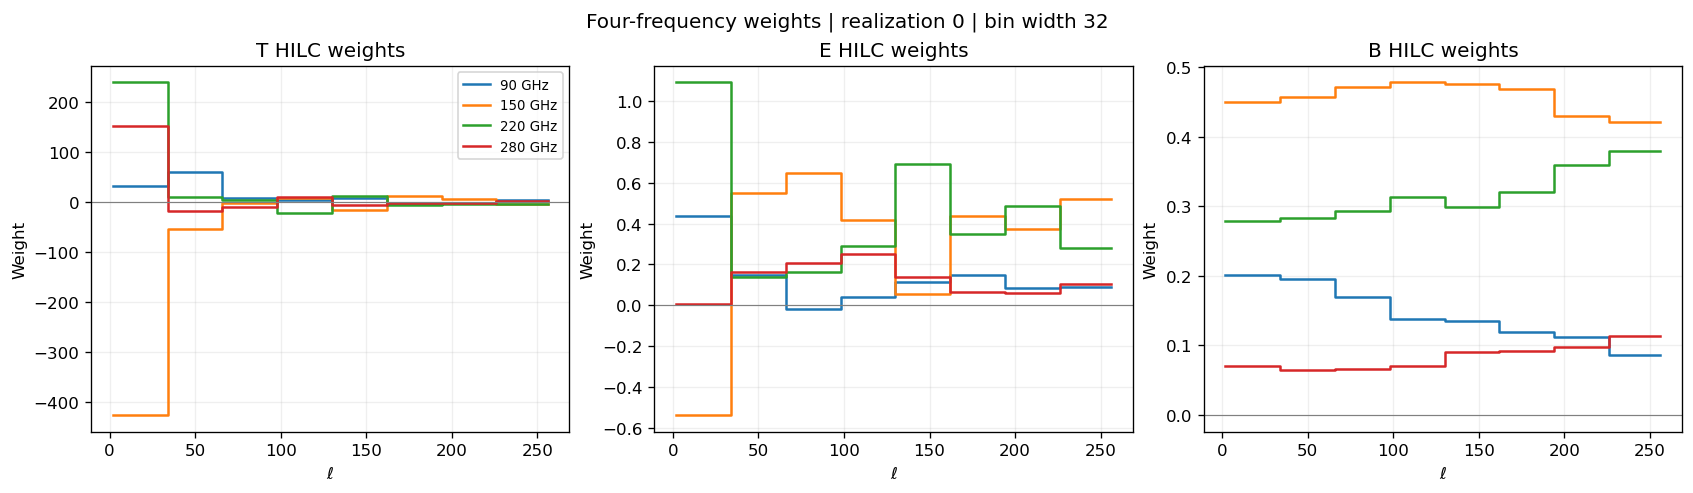

In [2]:
example_idx = sim_indices[0]
clean_example = hilc.cleaned_alms(example_idx)
weights = hilc.weights(example_idx)
ell = np.arange(lmax_hilc + 1)
dl = ell * (ell + 1) / (2 * np.pi)
np.testing.assert_allclose(weights.sum(axis=-1), 1., atol=1e-10)
assert np.isfinite(clean_example).all()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, layout='constrained')
for field, name in enumerate(['T', 'E', 'B']):
    for channel, freq in enumerate(freqs):
        axes[field].step(ell[2:], weights[field, 2:, 0, channel], where='post', label=f'{freq} GHz')
    axes[field].axhline(0, color='gray', lw=0.7)
    axes[field].set(title=f'{name} HILC weights', xlabel=r'$\ell$', ylabel='Weight')
axes[0].legend(fontsize=8)
fig.suptitle(f'Four-frequency weights | realization {example_idx} | bin width {hilc_bin_width}')
plt.show()

## Mean cleaned-noise spectra used for filtering
For each calibration realization, propagate its noise alms with its observed-sky weights and calculate TT, EE, BB noise spectra. Average the **powers** over the calibration set.

The curves below compare the mean residual HILC noise with beam-deconvolved channel white noise and the ideal inverse-noise combination $N_\ell^{\rm ideal}=(\sum_\nu 1/N_{\ell,\nu})^{-1}$. The latter uses fixed noise-optimal weights; empirical HILC need not attain this reference.

Noise calibration 100 complete (4.5 s)


Noise calibration 101 complete (9.3 s)


Noise calibration 102 complete (13.7 s)


Noise calibration 103 complete (18.5 s)


Noise calibration 104 complete (23.1 s)


Noise calibration 105 complete (28.7 s)


Noise calibration 106 complete (33.7 s)


Noise calibration 107 complete (38.6 s)


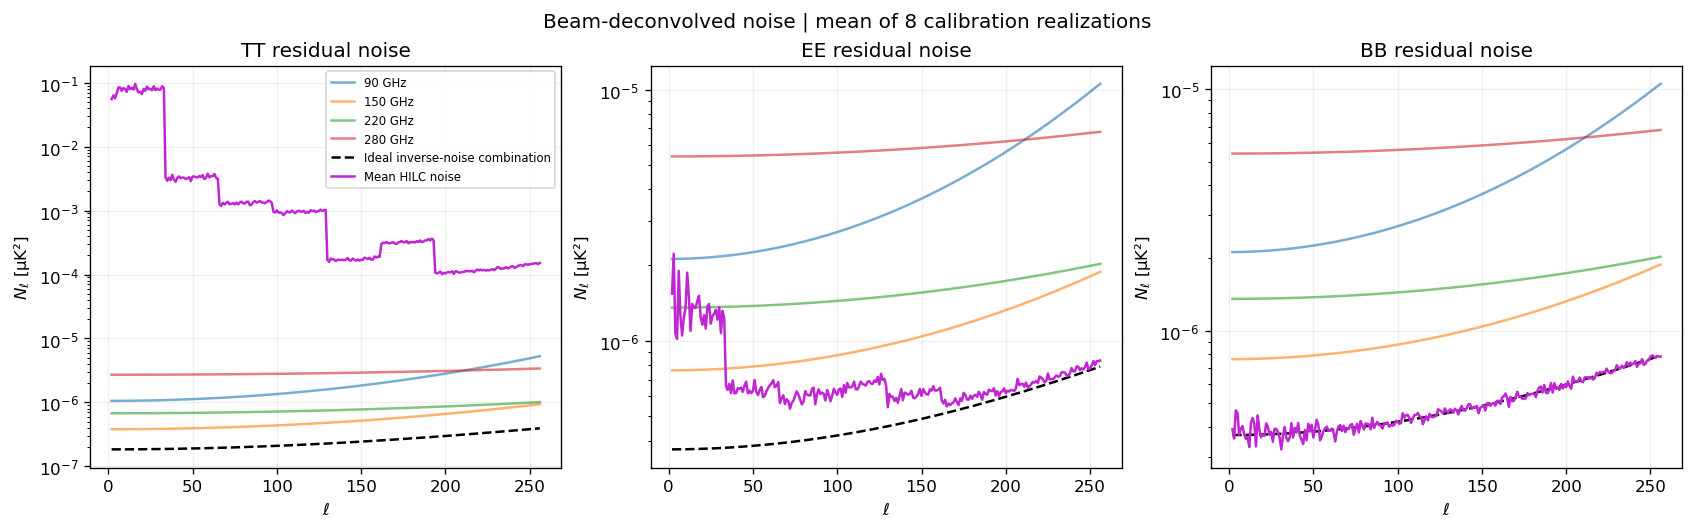

In [3]:
start = time.perf_counter()
noise_samples = []
for idx in noise_indices:
    noise_samples.append(hilc.noise_spectra(idx))
    print(f'Noise calibration {idx} complete ({time.perf_counter()-start:.1f} s)')
mean_noise = np.mean(noise_samples, axis=0)
np.testing.assert_allclose(mean_noise, hilc.mean_noise_spectra(noise_indices))

levels = np.column_stack([obs.nlevt, obs.nlevp, obs.nlevp])
channel_noise = (levels[:, :, None] * np.pi / (180*60) / hilc.beams)**2
ideal_noise = 1 / np.sum(1 / channel_noise, axis=0)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), layout='constrained')
for field, name in enumerate(['TT', 'EE', 'BB']):
    ax = axes[field]
    for channel, freq in enumerate(freqs):
        ax.plot(ell[2:], channel_noise[channel, field, 2:], alpha=0.6, label=f'{freq} GHz')
    ax.plot(ell[2:], ideal_noise[field, 2:], 'k--', label='Ideal inverse-noise combination')
    ax.plot(ell[2:], mean_noise[field, 2:], color='#c026d3', lw=1.5, label='Mean HILC noise')
    ax.set(title=f'{name} residual noise', xlabel=r'$\ell$',
           ylabel=r'$N_\ell$ [µK²]', yscale='log')
axes[0].legend(fontsize=7)
fig.suptitle(f'Beam-deconvolved noise | mean of {len(noise_indices)} calibration realizations')
plt.show()

## Cleaned CMB spectra
These are beam-deconvolved total auto-spectra: no residual-noise subtraction. The reference sky is the **actual spatially rotated CMB realization**, before channel beams/noise. It includes anisotropic-rotation changes in E/B power; the unrotated CAMB spectra are not the appropriate exact reference for this comparison.

The reference plus the propagated noise is not required to match each realization exactly: signal–noise cross-terms and empirical ILC correlations remain.

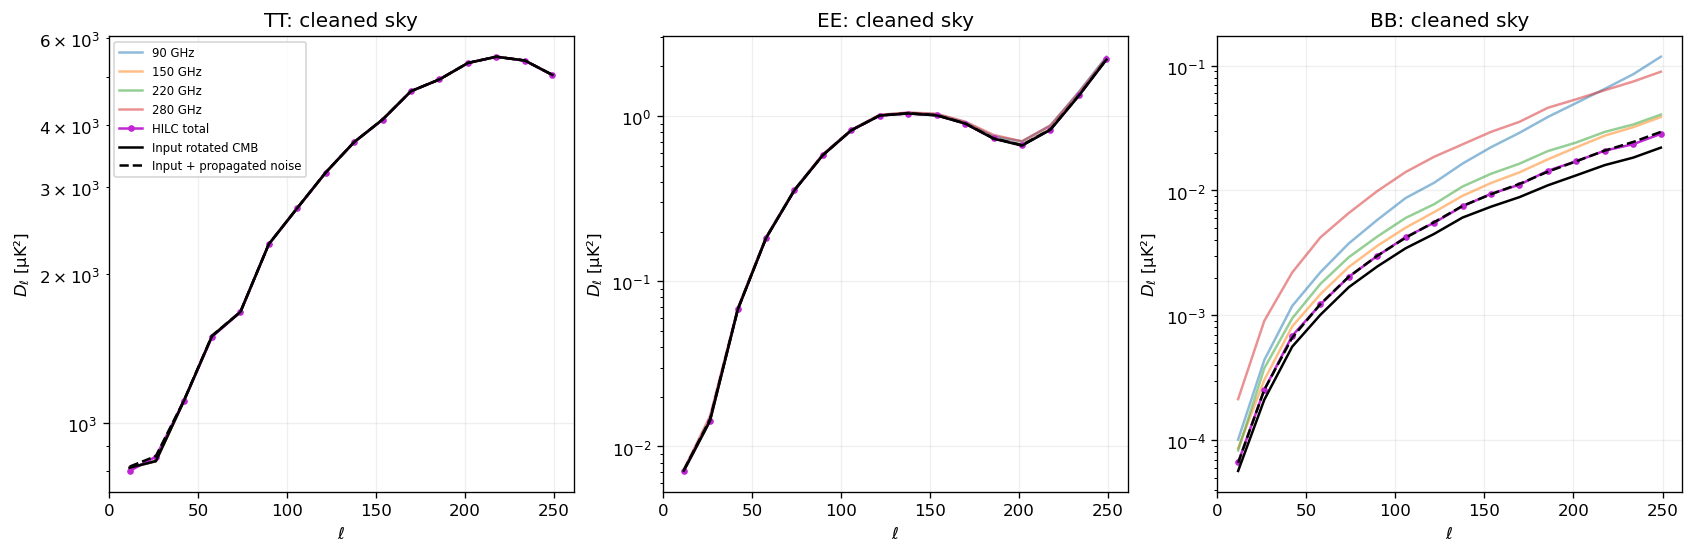

In [4]:
def make_binner(lmax, width):
    edges = np.append(np.arange(2, lmax+1, width), lmax+1)
    bins = [np.arange(a, b) for a, b in zip(edges[:-1], edges[1:])]
    weights = [(2*b+1)/np.sum(2*b+1) for b in bins]
    centers = np.array([np.sum(b*w) for b, w in zip(bins, weights)])
    factor = np.arange(lmax+1) * np.arange(1, lmax+2) / (2*np.pi)
    def bin_dl(cls):
        return np.stack([np.sum(cls[..., b]*factor[b]*w, axis=-1)
                         for b, w in zip(bins, weights)], axis=-1)
    return centers, bin_dl

cmb_centers, bin_cmb = make_binner(lmax_hilc, 16)
raw_maps = obs.observedmap(example_idx)
raw_alms = np.array([hp.map2alm(sky, lmax=lmax_hilc, iter=3) for sky in raw_maps])
for channel in range(len(freqs)):
    for field in range(3):
        hp.almxfl(raw_alms[channel, field], 1/hilc.beams[channel, field], inplace=True)
channel_cls = np.array([[hp.alm2cl(alm) for alm in sky] for sky in raw_alms])
clean_cls = np.array([hp.alm2cl(alm) for alm in clean_example])
truth_teb = hp.map2alm(obs.cmbrotated(example_idx), lmax=lmax_hilc, iter=3)
truth_cls = np.array([hp.alm2cl(alm) for alm in truth_teb])
noise_example = hilc.noise_spectra(example_idx)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout='constrained')
for field, name in enumerate(['TT', 'EE', 'BB']):
    ax = axes[field]
    for channel, freq in enumerate(freqs):
        ax.plot(cmb_centers, bin_cmb(channel_cls[channel, field]), alpha=0.5, label=f'{freq} GHz')
    ax.plot(cmb_centers, bin_cmb(clean_cls[field]), 'o-', ms=3, color='#c026d3', label='HILC total')
    ax.plot(cmb_centers, bin_cmb(truth_cls[field]), color='black', label='Input rotated CMB')
    ax.plot(cmb_centers, bin_cmb(truth_cls[field]+noise_example[field]), 'k--', label='Input + propagated noise')
    ax.set(title=f'{name}: cleaned sky', xlabel=r'$\ell$', ylabel=r'$D_\ell$ [µK²]', yscale='log')
axes[0].legend(fontsize=7)
plt.show()
del raw_maps, raw_alms

## Reconstruct the rotation spectrum
`AlphaRecon` uses the mean HILC TT/EE/BB noise in `ftl`, `fel`, `fbl`, with unit beam transfer functions. The cleaned alms go directly to the harmonic filter.

For each independent test realization, compute normalized $\hat\alpha_{LM}$, its auto-spectrum, its cross-spectrum with the exact injected rotation, and the normalized semi-analytical $N_L^{(0)}$. The reconstruction ensemble does not overlap the filtering-noise ensemble. Error bars below are standard errors across realizations, not per-sky error bars.

In [5]:
rec = AlphaRecon(hilc, root / 'recon', noise_indices=noise_indices,
                 lmin_ivf=lmin_ivf, lmax_ivf=lmax_ivf, lmax_qlm=lmax_qlm)
for field, key in enumerate(['tt', 'ee', 'bb']):
    np.testing.assert_allclose(rec.noise_cls[key], mean_noise[field, :lmax_ivf+1])
for transfer in rec.transf.values():
    np.testing.assert_array_equal(transfer, 1.)

L = np.arange(lmax_qlm+1)
cl_aa = obs.cl_aa()[:lmax_qlm+1]
# Correct packed-alm truncation: slicing the first nalm elements is wrong.
ls, ms = hp.Alm.getlm(lmax_qlm)
truth_selection = hp.Alm.getidx(obs.lmax, ls, ms)
spectra = {key: [] for key in ['auto', 'cross', 'input', 'n0']}
start = time.perf_counter()
for idx in sim_indices:
    estimate = rec.reconstruct(idx)
    truth = obs.alpha_alm(idx)[truth_selection]
    spectra['auto'].append(hp.alm2cl(estimate))
    spectra['cross'].append(hp.alm2cl(estimate, truth))
    spectra['input'].append(hp.alm2cl(truth))
    spectra['n0'].append(rec.noise_spectrum(idx))
    print(f'Reconstruction {idx} complete ({time.perf_counter()-start:.1f} s)')
spectra = {key: np.asarray(value) for key, value in spectra.items()}
assert all(np.isfinite(value).all() for value in spectra.values())
assert np.all(spectra['n0'] >= 0)
print('Verified finite outputs and the use of mean HILC noise in the filters.')

/Users/antoidicherianlonappan/Software/plancklens/plancklens/utils.py:124: RuntimeWarning: overflow encountered in cast
  return hashlib.sha1(np.copy(cl.astype(dtype), order='C')).hexdigest()


Caching sky fractions...


Reconstruction 0 complete (0.3 s)


Reconstruction 1 complete (5.3 s)


Reconstruction 2 complete (10.4 s)


Reconstruction 3 complete (15.4 s)


Reconstruction 4 complete (20.5 s)


Reconstruction 5 complete (25.6 s)


Reconstruction 6 complete (30.7 s)


Reconstruction 7 complete (36.0 s)
Verified finite outputs and the use of mean HILC noise in the filters.


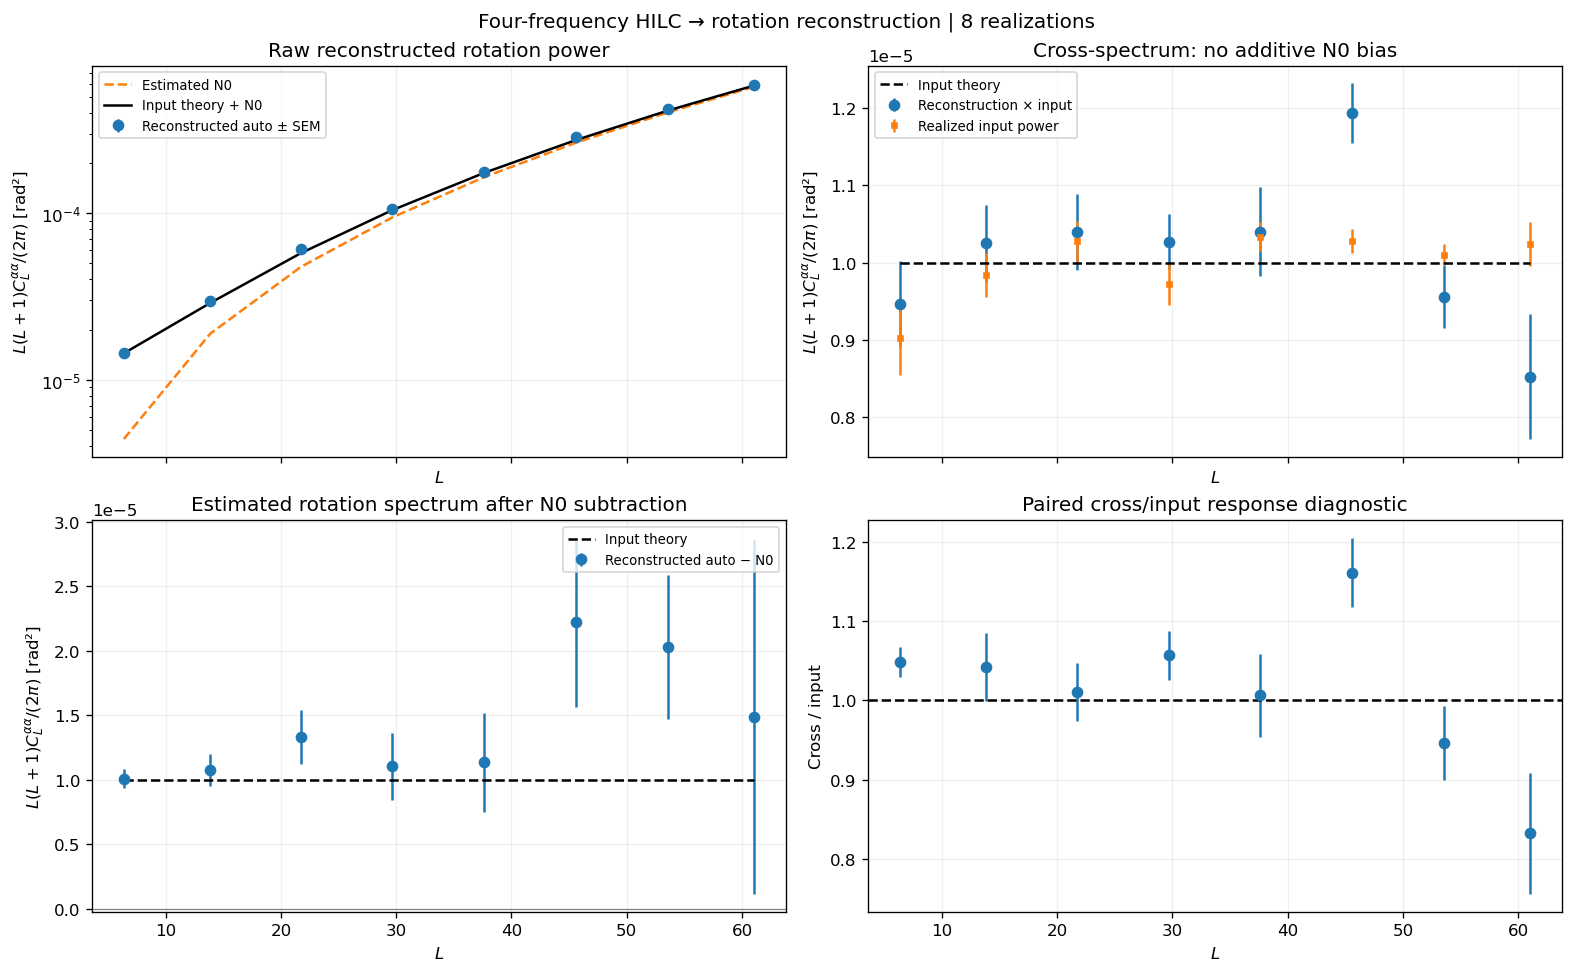

Equal-bin mean cross-minus-input residual: +0.012 ± 0.018 (SEM)
Saved per-realization spectra: data/four_frequency_demo/94a02d77d1df/rotation_spectra.npz


In [6]:
L_b, bin_rotation = make_binner(lmax_qlm, rotation_bin_width)
bands = {key: bin_rotation(value) for key, value in spectra.items()}
theory_b = bin_rotation(cl_aa)

def mean_sem(samples):
    return samples.mean(axis=0), samples.std(axis=0, ddof=1)/np.sqrt(len(samples))

auto, auto_err = mean_sem(bands['auto'])
cross, cross_err = mean_sem(bands['cross'])
input_mean, input_err = mean_sem(bands['input'])
n0 = bands['n0'].mean(axis=0)
debiased, debiased_err = mean_sem(bands['auto'] - bands['n0'])
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, layout='constrained')
ax = axes[0, 0]
ax.errorbar(L_b, auto, auto_err, fmt='o', label='Reconstructed auto ± SEM')
ax.plot(L_b, n0, '--', label='Estimated N0')
ax.plot(L_b, theory_b+n0, color='black', label='Input theory + N0')
ax.set(title='Raw reconstructed rotation power', yscale='log')
ax.legend(fontsize=8)
ax = axes[0, 1]
ax.errorbar(L_b, cross, cross_err, fmt='o', label='Reconstruction × input')
ax.errorbar(L_b, input_mean, input_err, fmt='s', ms=3, label='Realized input power')
ax.plot(L_b, theory_b, 'k--', label='Input theory')
ax.set_title('Cross-spectrum: no additive N0 bias')
ax.legend(fontsize=8)
ax = axes[1, 0]
ax.errorbar(L_b, debiased, debiased_err, fmt='o', label='Reconstructed auto − N0')
ax.plot(L_b, theory_b, 'k--', label='Input theory')
ax.axhline(0, color='gray', lw=0.7)
ax.set_title('Estimated rotation spectrum after N0 subtraction')
ax.legend(fontsize=8)
ax = axes[1, 1]
paired_mean, paired_err = mean_sem(bands['cross'] - bands['input'])
ax.errorbar(L_b, 1 + paired_mean/input_mean, paired_err/input_mean, fmt='o')
ax.axhline(1, color='black', ls='--')
ax.set(title='Paired cross/input response diagnostic', ylabel='Cross / input')
for ax in axes.flat:
    ax.set_xlabel('$L$')
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.set_ylabel(r'$L(L+1)C_L^{\alpha\alpha}/(2\pi)$ [rad²]')
fig.suptitle(f'Four-frequency HILC → rotation reconstruction | {len(sim_indices)} realizations')
plt.show()

# Report rather than force agreement: ILC and higher-order biases can remain.
fractional = ((bands['cross']-bands['input'])/theory_b).mean(axis=1)
mean, error = mean_sem(fractional)
print(f'Equal-bin mean cross-minus-input residual: {mean:+.3f} ± {error:.3f} (SEM)')
np.savez(root / 'rotation_spectra.npz', ell=L, theory=cl_aa,
         indices=np.asarray(sim_indices), **spectra)
print('Saved per-realization spectra:', root / 'rotation_spectra.npz')

## Interpreting the result
- The HILC plots show the combination and residual noise for this CMB-plus-noise experiment; they do not demonstrate foreground removal.
- The input cross-spectrum tests the effective reconstruction response after cleaning. Empirical ILC can alter that response through correlations between weights and signal.
- Subtracting the semi-analytical $N^{(0)}$ gives an estimated rotation auto-spectrum, not a fully bias-corrected measurement. ILC effects, connected biases such as N1, and higher-order rotation effects remain; no mean-field subtraction is made here.
- A small ensemble gives noisy error bars. Increase the disjoint calibration and reconstruction sets for more quantitative validation. No empirical rescaling is applied to make the reconstruction agree with the input.
- In the saved default run, the temperature weights have large cancelling values and the residual T noise is amplified. HILC does not improve every component. The `a_p` estimator uses polarization E/B, so temperature does not enter this reconstruction.